# Bicycle or Motorcycle? Image Classification with Keras

**Project 02 · Computer Vision · Convolutional Neural Networks**

Train a CNN to distinguish **bicycles** from **motorcycles** using the corresponding classes in CIFAR-100. This notebook follows a simple workflow: load the images, augment them, define a Functional Keras model, train for 10 epochs, inspect the loss curves, and test predictions on individual images.

**Class labels:** `0 = Bicycle`, `1 = Motorcycle`  
**Image format:** 32 × 32 RGB pixels

> **Dataset adaptation:** Unlike a folder-based dataset, CIFAR-100 is loaded directly through Keras. Its official test images are kept separate for the final evaluation. Because CIFAR-100 images are already 32 × 32 pixels, this model does not enlarge them to 64 × 64.

## 1. Load and prepare the data

**(a)** Load CIFAR-100, keep only the bicycle and motorcycle classes, and create `train_ds`, `val_ds`, and `test_ds`. Use batches of 16 images. The original training split is divided into training and validation subsets; the official test split is reserved for the final check.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    RandomTranslation,
    RandomZoom,
    RandomFlip,
    RandomRotation,
    RandomContrast,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
BATCH_SIZE = 16

# CIFAR-100 fine-label IDs: bicycle = 8, motorcycle = 48.
BICYCLE_ID = 8
MOTORCYCLE_ID = 48
# Change bicycle to 0 and motorcycle to 1
CLASS_NAMES = {0: "Bicycle", 1: "Motorcycle"}

(x_train_all, y_train_all), (x_test_all, y_test_all) = (
    tf.keras.datasets.cifar100.load_data(label_mode="fine")
)

# flattening into one-dimensional arrays
y_train_all = y_train_all.ravel()
y_test_all = y_test_all.ravel()

# Keeps only bicycles and motorcycles
train_mask = np.isin(y_train_all, [BICYCLE_ID, MOTORCYCLE_ID])
test_mask = np.isin(y_test_all, [BICYCLE_ID, MOTORCYCLE_ID])

# selecting the corresponding images (features) and labels (targets)
X_selected = x_train_all[train_mask]
y_selected_original = y_train_all[train_mask]  # 8,48

X_test = x_test_all[test_mask]
y_test_original = y_test_all[test_mask]        # 8,48

# Converting labels to binary flags and then binary values: 0 or 1
y_selected = (y_selected_original == MOTORCYCLE_ID).astype("int32")
y_test = (y_test_original == MOTORCYCLE_ID).astype("int32")


# Spliting training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_selected,
    y_selected,
    test_size=0.20,  # 20% of the selected training data to validation
    random_state=SEED,
    stratify=y_selected,
)

# Creating TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Class names:", [CLASS_NAMES[0], CLASS_NAMES[1]])
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Image shape:", X_train.shape[1:])

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2723s 16us/step
TensorFlow version: 2.21.0
GPU devices: []
Class names: ['Bicycle', 'Motorcycle']
Training images: 800
Validation images: 200
Test images: 200
Image shape: (32, 32, 3)


## 2. Create the augmentation layers

**(b)** Define five image-augmentation layers: translation and zoom up to 30%, horizontal flipping, rotation up to 30% of a full turn, and contrast adjustment up to 30%.

In [10]:
random_translation = RandomTranslation(
    height_factor=0.3,
    width_factor=0.3,
    name="random_translation",
)

random_zoom = RandomZoom(
    height_factor=0.3,
    width_factor=0.3,
    name="random_zoom",
)

random_flip = RandomFlip(
    mode="horizontal",
    name="random_flip",
)

random_rotation = RandomRotation(
    factor=0.3,
    name="random_rotation",
)

random_contrast = RandomContrast(
    factor=0.3,
    name="random_contrast",
)


data_augmentation = tf.keras.Sequential([
    random_translation,
    random_zoom,
    random_flip,
    random_rotation,
    random_contrast,
], name="data_augmentation")

**(c)** Run the following cell to compare 16 original images with augmented versions.

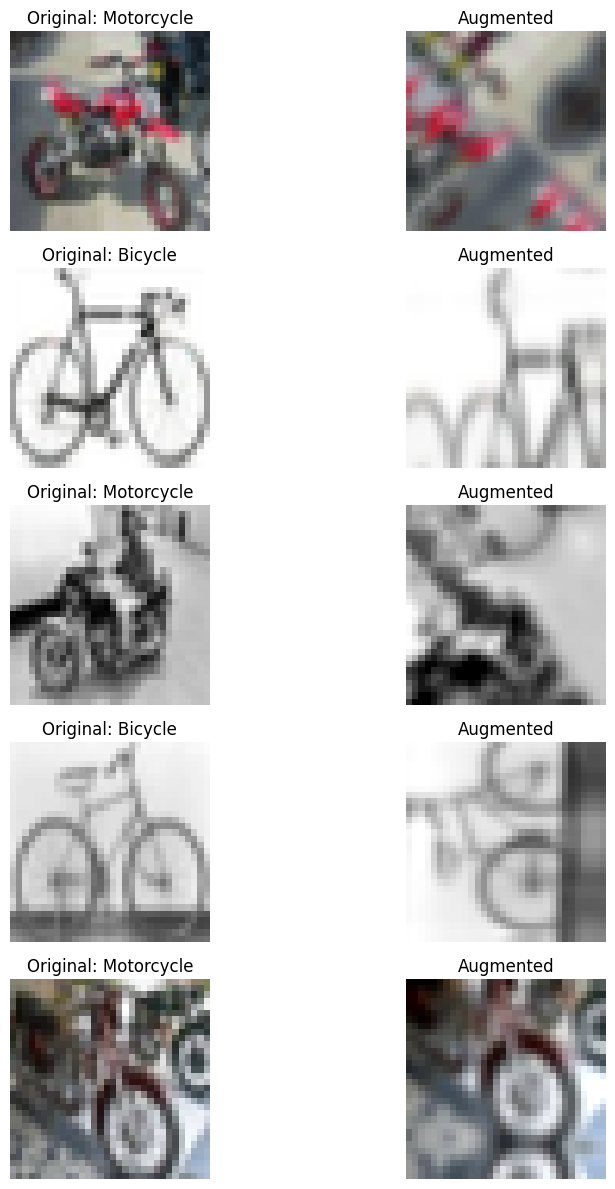

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

num_images = 5

plt.figure(figsize=(10, 12))

for i in range(num_images):
    original = X_train[i].astype("float32") / 255.0

    augmented = data_augmentation(
        tf.expand_dims(original, axis=0),
        training=True,
    )[0].numpy()

    # Original image
    plt.subplot(num_images, 2, 2 * i + 1)
    plt.imshow(original)
    plt.title(f"Original: {CLASS_NAMES[int(y_train[i])]}")
    plt.axis("off")

    # Augmented image
    plt.subplot(num_images, 2, 2 * i + 2)
    plt.imshow(np.clip(augmented, 0, 1))
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

** The additional photos created through data augmentation increase the variety of training examples by changing their position, orientation, zoom, and contrast. This helps the CNN learn important features that distinguish bicycles from motorcycles and improves its ability to classify new images.

## 3. Build the CNN

**(f)** Implement the network with the Keras Functional API. Apply augmentation, rescale RGB values to 0–1, then use two convolution-and-pooling blocks, a flattening layer, a 128-unit dense layer, and one sigmoid output. The input remains at CIFAR-100's native 32 × 32 resolution.

In [15]:
inputs = Input(shape=(32, 32, 3), name="input")

# Augmentation
x = random_translation(inputs)
x = random_zoom(x)
x = random_flip(x)
x = random_rotation(x)
x = random_contrast(x)

# Pixel scaling
x = Rescaling(1.0 / 255.0, name="rescaling")(x)

# Convolutional block 1 with kernel size (4, 4)
x = Conv2D(32, (4, 4), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)

# Convolutional block 2 with kernel size (4, 4)
x = Conv2D(32, (4, 4), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)

# Classification
x = Flatten()(x)
x = Dense(128, activation="relu")(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 32, 32, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,641 (471.25 KB)

 Trainable params: 120,641 (471.25 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compile and train

**(g)** Compile the model with Adam, binary cross-entropy, and accuracy. Train for 50 epochs and store the training history in `history`.

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.6012 - loss: 0.6591 - val_accuracy: 0.5800 - val_loss: 0.8050
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7100 - loss: 0.5552 - val_accuracy: 0.7650 - val_loss: 0.4974
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7450 - loss: 0.5376 - val_accuracy: 0.7100 - val_loss: 0.5341
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7200 - loss: 0.5585 - val_accuracy: 0.7100 - val_loss: 0.5459
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.7437 - loss: 0.5420 - val_accuracy: 0.6800 - val_loss: 0.5906
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7563 - loss: 0.5137 - val_accuracy: 0.7000 - val_loss: 0.5465
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7487 - loss: 0.5045 - val_accuracy: 0.6500 - val_loss: 0.6864
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7525 - loss: 0.4999 - val_accuracy: 0.6850 - v

## Analysis

1. **Unstable validation accuracy:** Validation accuracy fluctuated between 58% and 81% during training.

2. **Small dataset:** The model was trained on only 800 images, which may limit its ability to generalize to unseen images.

3. **Best performance:** The highest validation accuracy was 81%, achieved at epoch 20.

4. **Classification difficulty:** Bicycles and motorcycles may share visually similar features, making them harder to distinguish.

5. **Data augmentation:** Random transformations may introduce additional variability and affect the model's performance.

## 5. Review the training curves

**(h)** Plot training and validation loss across the completed epochs. Describe their trends and discuss any signs of overfitting.

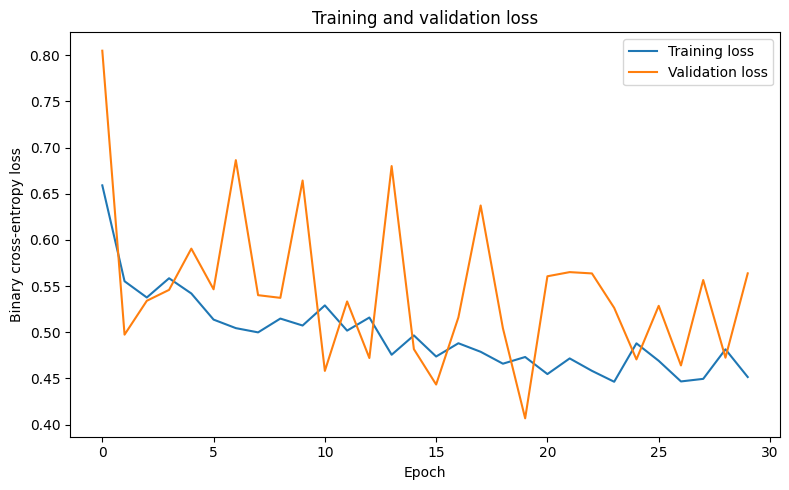

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

Conclusion: The model shows steady improvement during training, as indicated by the gradual decrease in training loss. However, the validation loss fluctuates considerably, suggesting that the model’s performance on unseen data is not yet consistent. To improve the model’s generalization performance, early stopping was introduced to monitor the validation loss during training. Training was allowed to continue for up to 50 epochs, with a patience of 10 epochs to prevent premature stopping due to temporary fluctuations in validation loss. The model weights from the epoch with the lowest validation loss were then restored. This approach helps reduce the risk of overfitting and retains the model’s best observed performance on the validation dataset.

## 6. Try predictions on individual images

**(i)** Select one motorcycle image from the held-out test set. Display the image and the model's predicted class with its confidence percentage. Here, the sigmoid output represents the predicted probability of **Motorcycle**.

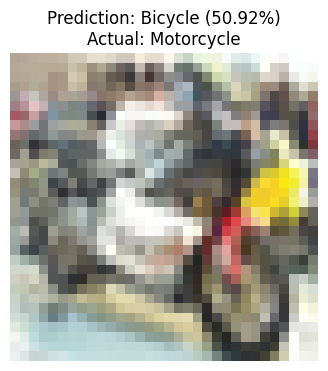

In [29]:
# Choose a known motorcycle example from the test set.
test_index = int(np.flatnonzero(y_test == 1)[0])
test_image = X_test[test_index]

proba = float(model.predict(np.expand_dims(test_image, axis=0), verbose=0)[0][0])
if proba >= 0.5:
    bicycle_or_motorcycle = "Motorcycle"
    confidence = 100 * proba
else:
    bicycle_or_motorcycle = "Bicycle"
    confidence = 100 * (1 - proba)

plt.figure(figsize=(4, 4))
plt.imshow(test_image)
plt.axis("off")
plt.title(
    f"Prediction: {bicycle_or_motorcycle} ({confidence:.2f}%)\n"
    f"Actual: {CLASS_NAMES[int(y_test[test_index])] }"
)
plt.show()

**(j)** Repeat the prediction for four more held-out images. Compare each prediction with the known label.

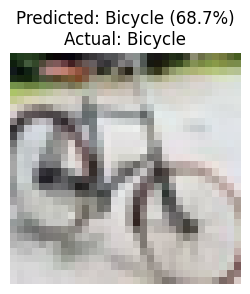

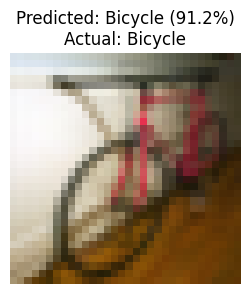

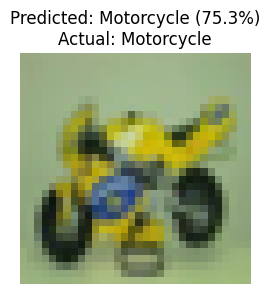

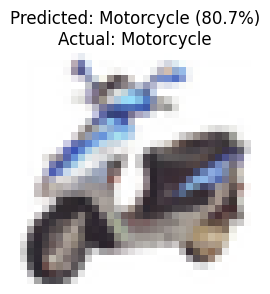

In [30]:
# Select two bicycles and two motorcycles, excluding the image shown above.
bicycle_indices = np.flatnonzero(y_test == 0)[:2]
motorcycle_indices = np.flatnonzero(y_test == 1)[1:3]
sample_indices = np.concatenate([bicycle_indices, motorcycle_indices])

for idx in sample_indices:
    test_image = X_test[idx]
    proba = float(model.predict(np.expand_dims(test_image, axis=0), verbose=0)[0][0])

    if proba >= 0.5:
        bicycle_or_motorcycle = "Motorcycle"
        confidence = 100 * proba
    else:
        bicycle_or_motorcycle = "Bicycle"
        confidence = 100 * (1 - proba)

    plt.figure(figsize=(3, 3))
    plt.imshow(test_image)
    plt.axis("off")
    plt.title(
        f"Predicted: {bicycle_or_motorcycle} ({confidence:.1f}%)\n"
        f"Actual: {CLASS_NAMES[int(y_test[idx])] }"
    )
    plt.show()

## 7. Final test-set check

Use the official test subset only after training is complete. Report accuracy and the per-class precision, recall, and F1-score, then inspect the confusion matrix.

Test accuracy: 0.840

              precision    recall  f1-score   support

     Bicycle      0.895     0.770     0.828       100
  Motorcycle      0.798     0.910     0.850       100

    accuracy                          0.840       200
   macro avg      0.847     0.840     0.839       200
weighted avg      0.847     0.840     0.839       200



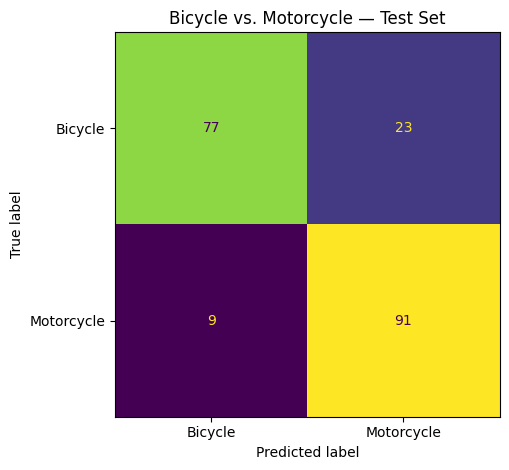

In [31]:
test_prob_motorcycle = model.predict(test_ds, verbose=0).ravel()
y_pred = (test_prob_motorcycle >= 0.5).astype("int32")

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]],
)
cm_display.plot(values_format="d", colorbar=False)
plt.title("Bicycle vs. Motorcycle — Test Set")
plt.tight_layout()
plt.show()

The model achieved a test accuracy of 84%, correctly classifying 168 out of 200 images. It performed better at identifying motorcycles, achieving a recall of 91%, compared with 77% for bicycles. Although the model demonstrated good overall classification performance, it misclassified 23 bicycles as motorcycles and 9 motorcycles as bicycles. These results suggest that the model is more effective at recognizing motorcycles but has some difficulty distinguishing bicycles from motorcycles. Further improvements, such as increasing the diversity of the training data and applying data augmentation, could help improve classification performance, particularly for bicycles.
